In [1]:
import torch
//torch.cuda.is_available() checks whether CUDA is available.
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
//torch.cuda.get_device_name(0) displays the GPU name
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available. Enable GPU in Runtime settings.")
//CUDA allows PyTorch to execute supported operations on NVIDIA GPUs

PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU Name: Tesla T4


In [19]:
!pip install psutil -q

import torch
import torch.nn as nn
import time
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import subprocess

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Execution Device:", device)


Execution Device: cuda


In [5]:
class SimpleCNN(nn.Module):

    def __init__(self):
        super(SimpleCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = SimpleCNN()
model = model.to(device)

model.eval()

print(model)


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [6]:
batch_size = 64

input_data = torch.randn(
    batch_size, 3, 32, 32
)

print("Input Shape:", input_data.shape)
print("Input Data Type:", input_data.dtype)


Input Shape: torch.Size([64, 3, 32, 32])
Input Data Type: torch.float32


In [7]:
# Move input data to GPU
gpu_input = input_data.to(device)

# Disable gradient calculation during inference
with torch.no_grad():

    # Warm-up execution
    for _ in range(10):
        output = model(gpu_input)

    # Synchronize GPU before timing
    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.time()

    for _ in range(100):
        output = model(gpu_input)

    if device.type == "cuda":
        torch.cuda.synchronize()

    end_time = time.time()

total_time = end_time - start_time

avg_latency = (total_time / 100) * 1000

throughput = (batch_size * 100) / total_time

print("Output Shape:", output.shape)
print("Average Latency:", round(avg_latency, 3), "ms")
print("Throughput:", round(throughput, 2), "images/sec")


Output Shape: torch.Size([64, 10])
Average Latency: 0.427 ms
Throughput: 149897.79 images/sec


In [8]:
# Create CPU model
cpu_model = SimpleCNN()
cpu_model.eval()

cpu_input = input_data

def benchmark(model, data, iterations=50):

    with torch.no_grad():

        # Warm-up
        for _ in range(5):
            model(data)

        if data.device.type == "cuda":
            torch.cuda.synchronize()

        start = time.time()

        for _ in range(iterations):
            model(data)

        if data.device.type == "cuda":
            torch.cuda.synchronize()

        end = time.time()

    return ((end - start) / iterations) * 1000


cpu_latency = benchmark(cpu_model, cpu_input)

if torch.cuda.is_available():

    gpu_model = cpu_model.to("cuda")
    gpu_input = cpu_input.to("cuda")

    gpu_latency = benchmark(gpu_model, gpu_input)

else:
    gpu_latency = None

print("CPU Latency:", round(cpu_latency, 3), "ms")

if gpu_latency is not None:
    print("GPU Latency:", round(gpu_latency, 3), "ms")


CPU Latency: 16.596 ms
GPU Latency: 0.428 ms


In [9]:
if torch.cuda.is_available():

    transfer_data = torch.randn(
        64, 3, 32, 32
    )

    torch.cuda.synchronize()

    start = time.time()

    for _ in range(100):
        transferred = transfer_data.to("cuda")

    torch.cuda.synchronize()

    end = time.time()

    transfer_latency = ((end - start) / 100) * 1000

    print(
        "Average Transfer Time:",
        round(transfer_latency, 3),
        "ms"
    )

else:
    print("GPU unavailable; transfer test skipped.")


Average Transfer Time: 0.308 ms


In [10]:
if torch.cuda.is_available():

    torch.cuda.reset_peak_memory_stats()

    gpu_input = input_data.to("cuda")
    gpu_model = cpu_model.to("cuda")

    with torch.no_grad():
        output = gpu_model(gpu_input)

    torch.cuda.synchronize()

    allocated_memory = (
        torch.cuda.memory_allocated() / (1024 ** 2)
    )

    reserved_memory = (
        torch.cuda.memory_reserved() / (1024 ** 2)
    )

    peak_memory = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
    )

    print("Allocated GPU Memory:", round(allocated_memory, 2), "MB")
    print("Reserved GPU Memory:", round(reserved_memory, 2), "MB")
    print("Peak GPU Memory:", round(peak_memory, 2), "MB")

else:
    print("GPU memory monitoring requires CUDA.")


Allocated GPU Memory: 11.68 MB
Reserved GPU Memory: 26.0 MB
Peak GPU Memory: 19.68 MB


In [11]:
batch_sizes = [1, 8, 16, 32, 64, 128]

latencies = []
throughputs = []

for bs in batch_sizes:

    test_input = torch.randn(
        bs, 3, 32, 32
    ).to(device)

    latency = benchmark(model, test_input, iterations=50)

    latencies.append(latency)

    throughput = (bs * 1000) / latency
    throughputs.append(throughput)

    print(
        "Batch:", bs,
        "| Latency:", round(latency, 3), "ms",
        "| Throughput:", round(throughput, 2), "images/sec"
    )


Batch: 1 | Latency: 0.273 ms | Throughput: 3656.82 images/sec
Batch: 8 | Latency: 0.329 ms | Throughput: 24292.27 images/sec
Batch: 16 | Latency: 0.291 ms | Throughput: 54940.62 images/sec
Batch: 32 | Latency: 0.343 ms | Throughput: 93366.26 images/sec
Batch: 64 | Latency: 0.428 ms | Throughput: 149642.92 images/sec
Batch: 128 | Latency: 0.833 ms | Throughput: 153645.42 images/sec


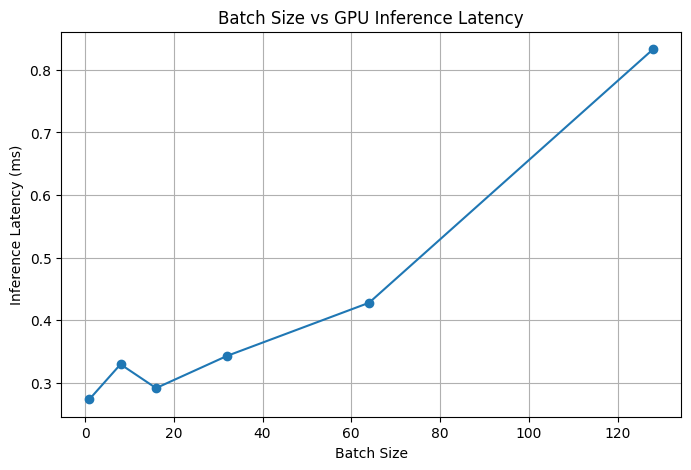

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    batch_sizes,
    latencies,
    marker="o"
)

plt.xlabel("Batch Size")
plt.ylabel("Inference Latency (ms)")
plt.title("Batch Size vs GPU Inference Latency")

plt.grid(True)
plt.show()


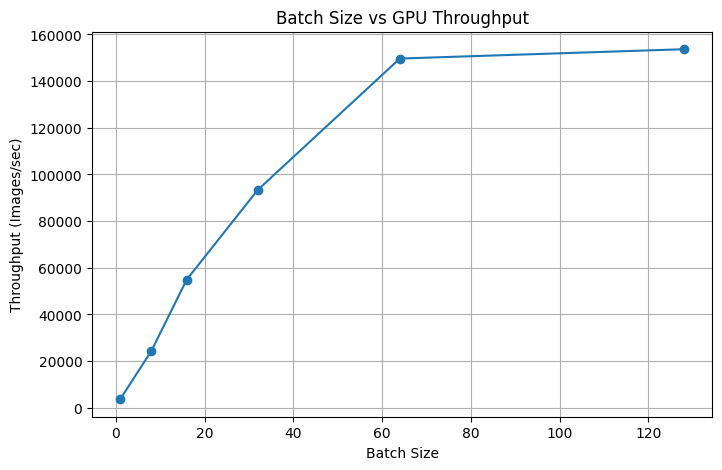

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    batch_sizes,
    throughputs,
    marker="o"
)

plt.xlabel("Batch Size")
plt.ylabel("Throughput (Images/sec)")
plt.title("Batch Size vs GPU Throughput")

plt.grid(True)
plt.show()


In [14]:
if torch.cuda.is_available():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=utilization.gpu,memory.used,memory.total",
            "--format=csv"
        ],
        capture_output=True,
        text=True
    )

    print(result.stdout)

else:
    print("No NVIDIA GPU detected.")


utilization.gpu [%], memory.used [MiB], memory.total [MiB]
0 %, 181 MiB, 15360 MiB



In [15]:
cpu_usage = psutil.cpu_percent(interval=1)

ram_usage = psutil.virtual_memory().percent

print("CPU Usage:", cpu_usage, "%")
print("RAM Usage:", ram_usage, "%")


CPU Usage: 2.0 %
RAM Usage: 16.8 %


In [16]:
results = pd.DataFrame({
    "Batch Size": batch_sizes,
    "Latency (ms)": latencies,
    "Throughput (images/sec)": throughputs
})

results


,Batch Size,Latency (ms),Throughput (images/sec)
0,1,0.273461,3656.824007
1,8,0.329323,24292.273833
2,16,0.291224,54940.616302
3,32,0.342736,93366.256243
4,64,0.427685,149642.920216
5,128,0.833087,153645.423585
